In [1]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"  # Makes CUDA errors synchronous

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_mean_pool
from torch_geometric.data import Data
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch Version: {torch.__version__}")

c:\Users\u2251865\.conda\envs\tree4\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch Version: 2.10.0


In [2]:
# Best Practice for your Master Notebook
import os
from pathlib import Path

# Identify project root as the parent of the current 'src' directory
PROJECT_ROOT = Path.cwd().parent
data_path = PROJECT_ROOT / 'data' / 'processed' / 'graph_data.pt'

print(f"Targeting data at: {data_path}")

Targeting data at: c:\Users\u2251865\Documents\u2251865\Project_2.0\NSCLC_dissertation\data\processed\graph_data.pt


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_mean_pool

class GraphEncoder(nn.Module):
    def __init__(self, node_features=8, edge_features=5, global_features=2, 
                 hidden_dim=128, latent_dim=64, num_layers=3, dropout=0.2, **kwargs):
        super().__init__()
        self.node_encoder = nn.Linear(node_features, hidden_dim)
        self.edge_encoder = nn.Linear(edge_features, hidden_dim)
        self.convs = nn.ModuleList([
            GINEConv(nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))) 
            for _ in range(num_layers)
        ])
        self.dropout = nn.Dropout(dropout)
        self.latent_dim = latent_dim
        
        # --- FIX: Initialize here based on expected input dimension ---
        # In GraphEncoder __init__:
        # Ensure the input_dim matches your concatenated size (128 + 2 = 130)
        input_dim = hidden_dim + 2 
        self.to_mu = nn.Linear(input_dim, latent_dim)
        self.to_logvar = nn.Linear(input_dim, latent_dim)

    def forward(self, x, edge_index, edge_attr, batch, global_features):
        x = F.relu(self.node_encoder(x))
        edge_attr = F.relu(self.edge_encoder(edge_attr))
        for conv in self.convs:
            x = F.relu(conv(x, edge_index, edge_attr))
            x = self.dropout(x)
        
        # 1. Pool nodes into graph embeddings [Batch_Size, Hidden_Dim]
        # Pool nodes into graph embeddings [Batch_Size, Hidden_Dim]
        graph_emb = global_mean_pool(x, batch)
        batch_size = graph_emb.size(0)

        # --- GLOBAL FEATURES HANDLING ---

        # 0. Guarantee 2D: [N, F] — must come before any slicing
        if global_features.dim() == 1:
            global_features = global_features.unsqueeze(0)  # [F] → [1, F]

        # 1. If more rows than graphs, take the first occurrence per graph
        if global_features.size(0) > batch_size:
            first_indices = torch.unique(batch, sorted=True)
            global_features = global_features[first_indices]

        # 2. Ensure last dimension is exactly 2
        if global_features.size(-1) != 2:
            global_features = global_features[:, :2]

        # 3. Batch size mismatch — pad by broadcasting or trim
        if global_features.size(0) != batch_size:
            if global_features.size(0) < batch_size:
                global_features = global_features.expand(batch_size, -1)
            else:
                global_features = global_features[:batch_size]
            

        # ... (all your existing Global Features Handling code) ...

        graph_emb = torch.cat([graph_emb, global_features], dim=-1)
        
        # 1. Generate the raw mu and logvar
        mu = self.to_mu(graph_emb)
        logvar = self.to_logvar(graph_emb)
        
        # 2. Apply clamping to stabilize the KL Divergence
        mu = torch.clamp(mu, min=-10.0, max=10.0)
        logvar = torch.clamp(logvar, min=-10.0, max=2.0)
        
        # 3. Return the clamped versions
        return mu, logvar



class GraphDecoder(nn.Module):
    def __init__(self, latent_dim=64, hidden_dim=128, pocket_dim=133, max_nodes=50, 
                 node_features=8, edge_features=5, dropout=0.2, use_pocket=True, **kwargs):
        super().__init__()
        self.max_nodes = max_nodes
        self.node_features = node_features
        self.edge_features = edge_features
        self.pocket_proj = nn.Linear(pocket_dim, hidden_dim // 2) if use_pocket else None
        expand_input = latent_dim + (hidden_dim // 2 if use_pocket else 0)
        self.mlp_expand = nn.Sequential(
            nn.Linear(expand_input, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU()
        )
        self.node_decoder = nn.Linear(hidden_dim, max_nodes * node_features)
        self.adj_decoder = nn.Linear(hidden_dim, max_nodes * max_nodes)
        self.type_decoder = nn.Linear(hidden_dim, max_nodes * max_nodes * edge_features)

    def forward(self, z, pocket_embedding=None):
        h = z
        if self.pocket_proj is not None and pocket_embedding is not None:
            # 1. Slice to the correct initial dimension
            if pocket_embedding.size(-1) != 133:
                pocket_embedding = pocket_embedding[..., :133]
                
            # 2. Project the pocket into the hidden space
            p_emb = self.pocket_proj(pocket_embedding)
            
            # 3. --- DIMENSION ALIGNMENT FIX ---
            # If the pocket is a 1D vector, add a batch dimension to make it 2D
            if p_emb.dim() == 1:
                p_emb = p_emb.unsqueeze(0)  # Turns [64] into [1, 64]
                
            # If the pocket tensor doesn't match the batch size of z, 
            # broadcast (copy) it for every graph in the batch.
            if p_emb.size(0) != z.size(0):
                p_emb = p_emb.expand(z.size(0), -1)  # Turns [1, 64] into [32, 64]
                
            h = torch.cat([z, p_emb], dim=-1)
            
        h = self.mlp_expand(h)
        node_logits = self.node_decoder(h).view(-1, self.max_nodes, self.node_features)
        adj_logits = self.adj_decoder(h).view(-1, self.max_nodes, self.max_nodes)
        type_logits = self.type_decoder(h).view(-1, self.max_nodes, self.max_nodes, self.edge_features)
        return node_logits, adj_logits, type_logits


class GraphVAE(nn.Module):
    def __init__(self, **kwargs):
        super().__init__()
        self.beta = kwargs.get('beta', 1.0)
        self.latent_dim = kwargs.get('latent_dim', 64)
        self.encoder = GraphEncoder(**kwargs)
        self.decoder = GraphDecoder(**kwargs)

    def reparameterize(self, mu, logvar):
        # --- THE FIX: Clamp logvar BEFORE exponentiating ---
        # A max of 10 means exp(5) = ~148, which is incredibly safe for FP16
        logvar = torch.clamp(logvar, min=-20.0, max=10.0)
        
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, edge_index, edge_attr, batch, global_features, pocket_embedding=None):
        mu, logvar = self.encoder(x, edge_index, edge_attr, batch, global_features)
        # Change to wider limits so the model has "room" to breathe
        mu = torch.clamp(mu, min=-50.0, max=50.0)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)
        z = self.reparameterize(mu, logvar)
        
        node_logits, adj_logits, type_logits = self.decoder(z, pocket_embedding)
        
        # CRITICAL STABILIZATION: Clamp the logits to prevent mathematical overflow
        # If logits > 20, the sigmoid/log operations become unstable
        node_logits = torch.clamp(node_logits, min=-20.0, max=20.0)
        adj_logits = torch.clamp(adj_logits, min=-20.0, max=20.0)
        type_logits = torch.clamp(type_logits, min=-20.0, max=20.0)
        
        return node_logits, adj_logits, type_logits, mu, logvar

    def loss_function(self, dense_x, dense_adj, edge_attr, node_logits, adj_logits, type_logits, mu, logvar):
        recon_node = F.cross_entropy(node_logits, dense_x, reduction='mean')
        recon_adj = F.binary_cross_entropy_with_logits(adj_logits, dense_adj, reduction='mean')
        
        # Combined Recon Loss
        recon_loss = recon_node + recon_adj

        # 3. Stable KL Divergence
        logvar = torch.clamp(logvar, min=-10, max=10)
        kl_loss = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
        self.beta = 1e-5

        # 4. Beta scaling (uses self.beta, not a hardcoded value)
        total_loss = recon_loss + (self.beta * kl_loss)
        # Inside your loss_function:
        # Instead of summing the whole KL, we only add the part that exceeds a threshold (e.g., 0.5)
        free_bits = 0.5 
        kl_loss = torch.max(kl_loss, torch.tensor(free_bits).to(kl_loss.device))


        return total_loss, recon_loss, kl_loss
    
    
   

In [4]:
from torch.utils.data import random_split

from torch_geometric.loader import DataLoader

# The '..' moves up one level from 'src' to 'NSCLC_dissertation'
data_path = '../data/processed/graph_data.pt'

# Verify this path exists before loading
if os.path.exists(data_path):
    print("Path confirmed: File found.")
else:
    print(f"File not found at: {os.path.abspath(data_path)}")

    
def load_and_prepare_data(filepath, batch_size=32):
    # 1. Load the dictionary
    container = torch.load(filepath, weights_only=False)
    
    # 2. Extract the actual list of PyG Data objects
    dataset = container['graphs']
    print(f"Successfully extracted {len(dataset)} molecular graphs.")
    
    # 3. Calculate split lengths
    total_size = len(dataset)
    train_size = int(0.8 * total_size)
    val_size = total_size - train_size
    
    # 4. Perform the split
    train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
    
    # 5. Create loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader

# Now run this, and you will see the correct numbers
train_loader, val_loader = load_and_prepare_data(r"C:\Users\u2251865\Documents\u2251865\Project_2.0\NSCLC_dissertation\data\processed\graph_data.pt")

Path confirmed: File found.
Successfully extracted 19846 molecular graphs.


In [5]:
config = {
    'node_features': 8,
    'edge_features': 5,
    'global_features': 2,
    'hidden_dim': 128,
    'latent_dim': 64,
    'num_layers': 3,
    'dropout': 0.2,
    'pocket_dim': 133,
    'max_nodes': 50,
    'beta': 0.0001,
    'use_pocket': True
}

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = GraphVAE(**config).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Model initialized and moved to:", device)

Model initialized and moved to: cuda


In [ ]:
import torch
import torch.nn as nn
from torch_geometric.loader import DataLoader

# 1. Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = GraphVAE(**config).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-5, weight_decay=1e-5)
scaler = torch.amp.GradScaler('cuda')
# Updated scheduler initialization
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.5, 
    patience=5
)


# 2. Tracking Metrics
train_metrics = {'loss': [], 'recon': [], 'kl': []}
val_metrics   = {'loss': [], 'recon': [], 'kl': []}

# 3. Training Function
def train_epoch(model, loader, optimizer, scaler):
    model.train()
    t_loss, t_recon, t_kl = 0, 0, 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            node_logits, adj_logits, type_logits, mu, logvar = model(
                batch.x, batch.edge_index, batch.edge_attr, batch.batch,
                batch.global_features, batch.pocket_embedding
            )
            from torch_geometric.utils import to_dense_adj, to_dense_batch
            dense_adj = to_dense_adj(batch.edge_index, batch.batch, max_num_nodes=50)
            dense_x, _ = to_dense_batch(batch.x, batch.batch, max_num_nodes=50)
            loss, recon, kl = model.loss_function(
                dense_x, dense_adj, batch.edge_attr, node_logits, adj_logits, type_logits, mu, logvar
            )
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        t_loss += loss.item(); t_recon += recon.item(); t_kl += kl.item()
    n = len(loader)
    return t_loss/n, t_recon/n, t_kl/n

# 4. Validation Function
def val_epoch(model, loader):
    model.eval()
    v_loss, v_recon, v_kl = 0, 0, 0
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            with torch.amp.autocast('cuda'):
                node_logits, adj_logits, type_logits, mu, logvar = model(
                    # Add this inside your training loop after node_logits, ... = model(...)
                    batch.x, batch.edge_index, batch.edge_attr, batch.batch,
                    batch.global_features, batch.pocket_embedding
                )
                from torch_geometric.utils import to_dense_adj, to_dense_batch
                dense_adj = to_dense_adj(batch.edge_index, batch.batch, max_num_nodes=50)
                dense_x, _ = to_dense_batch(batch.x, batch.batch, max_num_nodes=50)
                loss, recon, kl = model.loss_function(
                    dense_x, dense_adj, batch.edge_attr, node_logits, adj_logits, type_logits, mu, logvar
                )
            v_loss += loss.item(); v_recon += recon.item(); v_kl += kl.item()
    n = len(loader)
    return v_loss/n, v_recon/n, v_kl/n

# 5. Full Loop
for epoch in range(20):
    tr_loss, tr_rec, tr_kl = train_epoch(model, train_loader, optimizer, scaler)
    vl_loss, vl_rec, vl_kl = val_epoch(model, val_loader)
    
    train_metrics['loss'].append(tr_loss); train_metrics['recon'].append(tr_rec); train_metrics['kl'].append(tr_kl)
    val_metrics['loss'].append(vl_loss); val_metrics['recon'].append(vl_rec); val_metrics['kl'].append(vl_kl)

    # After calling scheduler.step(val_loss) in your training loop:
    scheduler.step(vl_loss)
    # Optional: print the current LR to track when it drops
    current_lr = scheduler.get_last_lr()[0]
    print(f"Current Learning Rate: {current_lr:.6f}")
    
    print(f"Epoch {epoch:3d} | Train: {tr_loss:.4f} (Rec: {tr_rec:.4f}, KL: {tr_kl:.4f}) | Val: {vl_loss:.4f} (Rec: {vl_rec:.4f}, KL: {vl_kl:.4f})")

Current Learning Rate: 0.000050
Epoch   0 | Train: 427.6762 (Rec: 427.6468, KL: 2935.4714) | Val: 418.9795 (Rec: 418.9501, KL: 2940.9598)
Current Learning Rate: 0.000050
Epoch   1 | Train: 418.2949 (Rec: 418.2648, KL: 3012.7818) | Val: 415.2134 (Rec: 415.1827, KL: 3061.4236)
Current Learning Rate: 0.000050
Epoch   2 | Train: 415.1502 (Rec: 415.1194, KL: 3082.7234) | Val: 413.4001 (Rec: 413.3696, KL: 3048.8978)
Current Learning Rate: 0.000050
Epoch   3 | Train: 413.0767 (Rec: 413.0456, KL: 3108.1622) | Val: 410.8976 (Rec: 410.8665, KL: 3112.2358)
Current Learning Rate: 0.000050
Epoch   4 | Train: 411.4389 (Rec: 411.4076, KL: 3136.6130) | Val: 410.3391 (Rec: 410.3077, KL: 3145.2363)
Current Learning Rate: 0.000050
Epoch   5 | Train: 410.8114 (Rec: 410.7800, KL: 3141.6950) | Val: 410.3204 (Rec: 410.2895, KL: 3094.0715)
Current Learning Rate: 0.000050
Epoch   6 | Train: 410.5691 (Rec: 410.5377, KL: 3138.4830) | Val: 409.8196 (Rec: 409.7883, KL: 3127.7572)
Current Learning Rate: 0.000050
Ep

In [7]:
# Save the trained VAE parameters
torch.save(model.state_dict(), 'graph_vae_egfr_stable.pth')
print("Model weights saved successfully!")

Model weights saved successfully!


In [8]:
import numpy as np

def extract_latent_features(model, loader):
    model.eval()
    
    # Initialize TWO separate lists
    mu_list = []
    std_list = []
    
    with torch.no_grad():
        for batch in loader:
            # 1. Normalize biological inputs
            if batch.pocket_embedding is not None:
                batch.pocket_embedding = F.normalize(batch.pocket_embedding.float(), p=2, dim=-1)
            if batch.global_features is not None:
                batch.global_features = F.normalize(batch.global_features.float(), p=2, dim=-1)
                
            batch = batch.to(device)
            
            # 2. Pass through the ENCODER ONLY
            mu, logvar = model.encoder(
                batch.x, batch.edge_index, batch.edge_attr, batch.batch, batch.global_features
            )
            
            # --- THE ADDITION ---
            # 3. Calculate standard deviation from logvar
            # (Because we clamped logvar during training, this exp() is mathematically safe)
            std = torch.exp(0.5 * logvar)
            
            # 4. Store both vectors
            mu_list.append(mu.cpu().numpy())
            std_list.append(std.cpu().numpy())
            
    # Concatenate all batches into two massive datasets
    mu_array = np.concatenate(mu_list, axis=0)
    std_array = np.concatenate(std_list, axis=0)
    
    return mu_array, std_array

print("Extracting latent features (Mu and Std)...")
# Unpack the two returned arrays
gan_training_data_mu, gan_training_data_std = extract_latent_features(model, train_loader)

# Save both to your drive so you have them backed up
np.save('gan_training_features_mu.npy', gan_training_data_mu)
np.save('gan_training_features_std.npy', gan_training_data_std)

print(f"Extraction complete!")
print(f"Mu matrix shape: {gan_training_data_mu.shape}")
print(f"Std matrix shape: {gan_training_data_std.shape}")

Extracting latent features (Mu and Std)...
Extraction complete!
Mu matrix shape: (15876, 64)
Std matrix shape: (15876, 64)


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set academic plotting style
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

def plot_figure_1(epochs, total_loss, recon_loss, kl_loss):
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Plot Total and Reconstruction Loss on the primary y-axis
    color = 'tab:blue'
    ax1.set_xlabel('Epochs', fontweight='bold')
    ax1.set_ylabel('Reconstruction & Total Loss', color=color, fontweight='bold')
    ax1.plot(epochs, total_loss, label='Total Loss', color='navy', linewidth=2)
    ax1.plot(epochs, recon_loss, label='Reconstruction Loss', color='royalblue', linestyle='--')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.set_ylim(bottom=0)

    # Plot KL Divergence on a secondary y-axis (since it's scaled by beta)
    ax2 = ax1.twinx()  
    color = 'tab:red'
    ax2.set_ylabel('KL Divergence', color=color, fontweight='bold')
    ax2.plot(epochs, kl_loss, label='KL Divergence', color='crimson', linewidth=2)
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(bottom=0)

    plt.title("Figure 1: GraphVAE Training Trajectory (Loss & Regularization)", pad=20, fontsize=14, fontweight='bold')
    
    # Combine legends
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax2.legend(lines + lines2, labels + labels2, loc='upper right', frameon=True)

    plt.tight_layout()
    plt.savefig('figure_1_loss_trajectory.png', dpi=300)
    plt.show()

# Example execution (replace with your actual training lists):
# plot_figure_1(range(100), total_loss_list, recon_loss_list, kl_loss_list)

In [10]:
def plot_figure_2(mu_matrix, std_matrix):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    mu_flat = mu_matrix.flatten()
    std_flat = std_matrix.flatten()

    # Plot Mu Distribution
    sns.histplot(mu_flat, bins=100, kde=True, color='teal', ax=ax1)
    # ADDED 'r' here
    ax1.set_title(r"Distribution of Latent Means ($\mu$)", fontweight='bold')
    ax1.set_xlabel("Feature Value")
    ax1.set_ylabel("Frequency")
    ax1.axvline(x=0, color='black', linestyle='--', alpha=0.7)

    # Plot Sigma Distribution
    sns.histplot(std_flat, bins=100, kde=True, color='purple', ax=ax2)
    # ADDED 'r' here
    ax2.set_title(r"Distribution of Latent Std Dev ($\sigma$)", fontweight='bold')
    ax2.set_xlabel("Feature Value")
    ax2.set_ylabel("Frequency")
    ax2.axvline(x=1, color='black', linestyle='--', alpha=0.7)

    plt.suptitle("Figure 2: 64D Latent Space Feature Stability", fontsize=14, fontweight='bold', y=1.05)
    
    sns.despine()
    plt.tight_layout()
    plt.savefig('figure_2_feature_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()

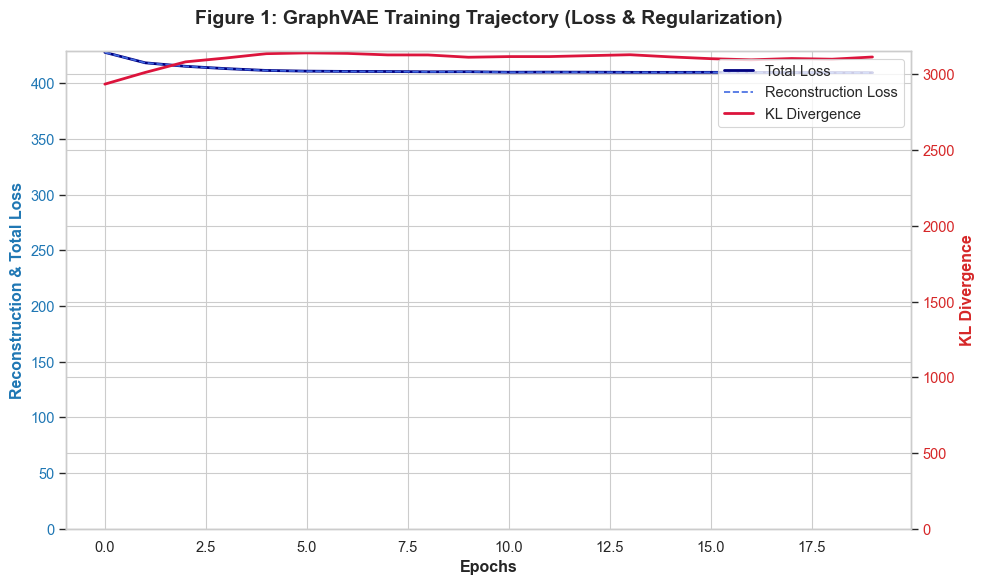

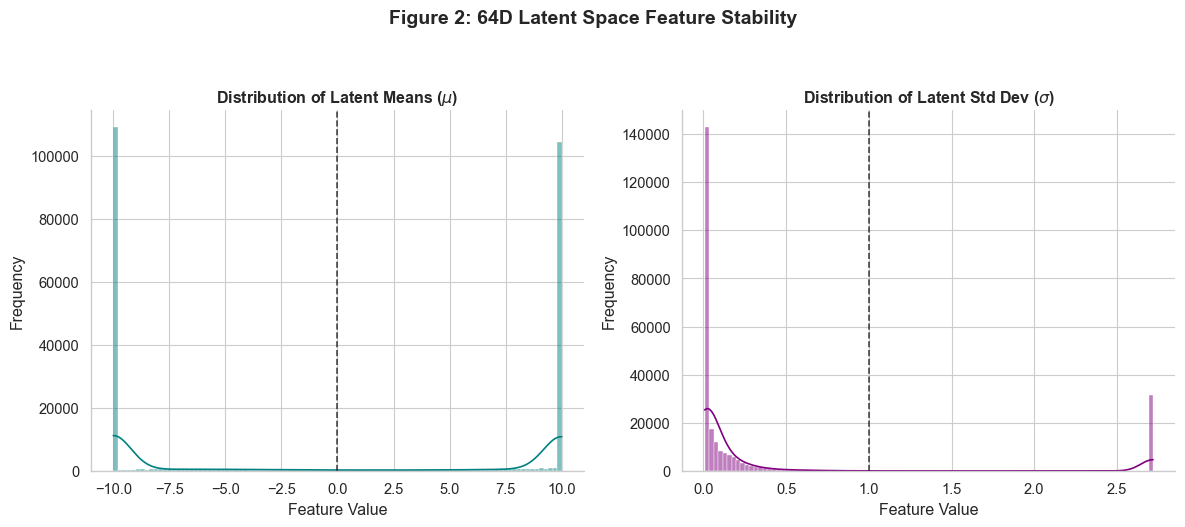

In [12]:
# 1. Plot the Loss Trajectory
# We use the length of the lists in your 'train_metrics' dictionary
actual_epochs = range(len(train_metrics['loss']))

# Use train_metrics['loss'] instead of total_loss_list
plot_figure_1(
    actual_epochs, 
    train_metrics['loss'], 
    train_metrics['recon'], 
    train_metrics['kl']
)

# 2. For the Latent Space plot
# You need to collect the actual latent vectors during a pass
# Run this helper to populate the variables 'gan_training_data_mu' and 'gan_training_data_std'
all_mu, all_std = [], []
model.eval()
with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(device)
        mu, logvar = model.encoder(batch.x, batch.edge_index, batch.edge_attr, batch.batch, batch.global_features)
        all_mu.append(mu.cpu())
        all_std.append(torch.exp(0.5 * logvar).cpu())

gan_training_data_mu = torch.cat(all_mu, dim=0)
gan_training_data_std = torch.cat(all_std, dim=0)

# Now call the plotting function
plot_figure_2(gan_training_data_mu, gan_training_data_std)